# 2. Kaplan-Meier: tiempos de resolución con casos censurados

1. Por qué el promedio de las cerradas está sesgado (experimento con un corte ficticio).
2. Curvas de Kaplan-Meier por agencia, tipo de queja, borough y canal, con medianas e IC 95 %.
3. Pruebas log-rank.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from nyc311.config import ARCHIVO_LIMPIO, ARCHIVO_RESULTADOS, DIR_FIGURAS, DIR_TABLAS

res = json.loads(ARCHIVO_RESULTADOS.read_text(encoding="utf-8"))
tabla = lambda nombre: pd.read_csv(DIR_TABLAS / f"{nombre}.csv")
figura = lambda nombre: display(Image(filename=str(DIR_FIGURAS / nombre)))

In [2]:
from nyc311.supervivencia import kaplan_meier, mediana_con_ic, logrank, tiempo_medio_restringido, evaluar
df = pd.read_parquet(ARCHIVO_LIMPIO, columns=["creada", "cerrada", "agencia", "tipo_queja", "borough", "canal",
                                              "duracion_dias", "evento"])
g = res["global"]
print(f"Mediana KM: {g['mediana_km_horas']:.2f} h (IC 95 %: {g['mediana_ic_inf_horas']:.2f}–{g['mediana_ic_sup_horas']:.2f})")
print(f"Promedio ingenuo de las cerradas: {g['promedio_ingenuo_cerradas_dias']:.2f} días")
print(f"% cerradas en 1 / 7 / 30 días: {g['pct_cerradas_1d']:.1f} / {g['pct_cerradas_7d']:.1f} / {g['pct_cerradas_30d']:.1f}")

Mediana KM: 8.95 h (IC 95 %: 8.92–8.99)
Promedio ingenuo de las cerradas: 8.72 días
% cerradas en 1 / 7 / 30 días: 59.1 / 81.1 / 90.6


## 2.1 La implementación propia coincide con lifelines

Con 7,5 M de filas y duraciones al segundo, `nyc311.supervivencia` agrega por tiempo único con numpy.
Las pruebas (`tests/test_supervivencia.py`) la comparan con lifelines y con el ejemplo de Freireich (leucemia).
Aquí, una comprobación rápida en una muestra:

In [3]:
from lifelines import KaplanMeierFitter
m = df.sample(50_000, random_state=311)
propia = kaplan_meier(m["duracion_dias"], m["evento"])
kmf = KaplanMeierFitter().fit(m["duracion_dias"], m["evento"])
print("mediana propia:", mediana_con_ic(propia)[0], "· lifelines:", kmf.median_survival_time_)
dif = np.abs(evaluar(propia, kmf.timeline) - kmf.survival_function_.iloc[:, 0].to_numpy()).max()
print(f"diferencia máxima entre curvas: {dif:.2e}")

mediana propia: 0.3625 · lifelines: 0.3625
diferencia máxima entre curvas: 1.28e-13


## 2.2 ¿Por qué no usar el promedio de las cerradas?

Experimento con datos reales: tomamos las solicitudes creadas en oct–dic 2024 y **fingimos** que la descarga se
hizo el 15-ene-2025. Comparamos lo que habríamos estimado entonces con la «verdad» que conocemos hoy (casi 2 años
de seguimiento).

In [4]:
exp = tabla("sesgo_corte_retrospectivo")
cols = ["grupo", "n", "pct_abiertas_corte_ficticio", "mediana_ingenua_ficticio", "mediana_km_ficticio",
        "mediana_verdad", "promedio_ingenuo_ficticio", "promedio_verdad_cerradas"]
exp[cols]

,grupo,n,pct_abiertas_corte_ficticio,mediana_ingenua_ficticio,mediana_km_ficticio,mediana_verdad,promedio_ingenuo_ficticio,promedio_verdad_cerradas
0,Todas,907223,7.015,0.378,0.558,0.558,3.531,11.559
1,DCWP,4379,7.559,2.848,3.123,3.123,11.305,13.578
2,DEP,55166,3.040,2.013,2.190,2.190,6.121,8.120
3,DHS,6278,6.579,0.291,0.359,0.359,3.218,8.036
4,DOB,25709,34.505,2.514,14.225,14.225,11.064,77.983
5,DOHMH,19811,14.941,1.000,2.604,2.604,20.621,25.574
6,DOT,45888,6.248,1.841,2.108,2.108,4.871,12.798
7,DPR,21559,40.823,4.646,27.228,27.231,12.991,78.031
8,DSNY,73806,2.284,1.256,1.312,1.312,3.292,4.631
9,EDC,7823,94.682,25.790,inf,171.032,25.698,142.052


In [5]:
for _, r in exp.loc[exp["grupo"].isin(["DOB", "DPR", "TLC"])].iterrows():
    print(f"{r['grupo']}: mediana ingenua {r['mediana_ingenua_ficticio']:.1f} d · KM {r['mediana_km_ficticio']:.1f} d · "
          f"verdad {r['mediana_verdad']:.1f} d · promedio ingenuo {r['promedio_ingenuo_ficticio']:.1f} d "
          f"vs promedio real {r['promedio_verdad_cerradas']:.1f} d")

DOB: mediana ingenua 2.5 d · KM 14.2 d · verdad 14.2 d · promedio ingenuo 11.1 d vs promedio real 78.0 d
DPR: mediana ingenua 4.6 d · KM 27.2 d · verdad 27.2 d · promedio ingenuo 13.0 d vs promedio real 78.0 d
TLC: mediana ingenua 25.6 d · KM 46.5 d · verdad 51.0 d · promedio ingenuo 26.0 d vs promedio real 63.2 d


**Lectura.** El promedio (o la mediana) de las cerradas solo ve a las que alcanzaron a cerrarse antes del corte:
por construcción descarta las lentas, y el sesgo es mayor donde más censura hay. Tratar las abiertas como si
cerraran en el corte tampoco sirve: las acorta. Kaplan-Meier usa la información parcial de las abiertas («llevaba
al menos X días») y recupera la mediana real. Cuando la mediana KM queda en «inf» (EDC) es honesto: con el
seguimiento disponible todavía no cerró la mitad.

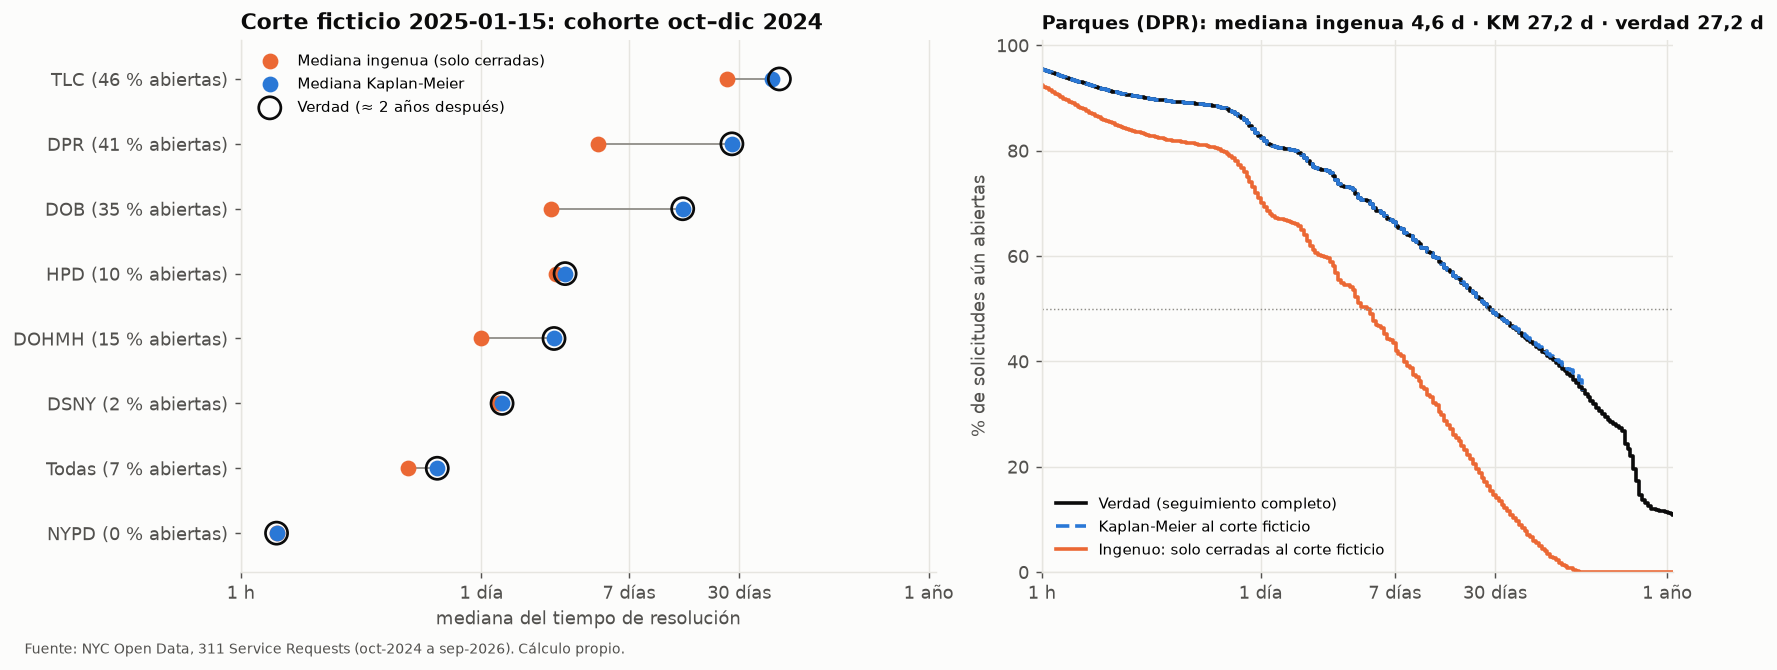

In [6]:
figura("02_sesgo_promedio_vs_kaplan_meier.png")

## 2.3 Kaplan-Meier por agencia, borough, canal y tipo de queja

In [7]:
tabla("km_agencias")[["agencia", "n", "pct_censuradas", "mediana_km_dias", "mediana_ic_inf", "mediana_ic_sup",
                       "pct_cerradas_1d", "pct_cerradas_7d", "pct_cerradas_30d", "promedio_ingenuo_cerradas_dias"]]

,agencia,n,pct_censuradas,mediana_km_dias,mediana_ic_inf,mediana_ic_sup,pct_cerradas_1d,pct_cerradas_7d,pct_cerradas_30d,promedio_ingenuo_cerradas_dias
0,NYPD,3404989,0.020,0.056,0.056,0.056,99.061,99.967,99.978,0.125
1,HPD,1647990,1.956,4.004,3.993,4.014,12.137,61.589,85.529,14.897
2,DSNY,686984,1.098,1.522,1.510,1.532,37.380,88.807,96.618,3.604
3,DOT,489985,4.719,2.472,2.420,2.517,37.421,68.272,89.864,9.384
4,DEP,427705,1.718,0.974,0.969,0.979,50.788,83.243,96.042,4.516
5,DPR,250070,23.085,19.033,18.819,19.406,18.595,38.771,55.115,41.452
6,DOB,220866,6.269,11.657,11.510,12.185,22.761,44.892,60.865,46.743
7,DOHMH,169211,6.414,5.095,4.966,5.262,33.787,52.143,62.549,22.609
8,DHS,88289,2.458,0.320,0.315,0.324,73.522,86.987,93.442,4.100
9,TLC,75493,34.226,122.468,120.011,124.658,6.275,18.366,27.789,80.618


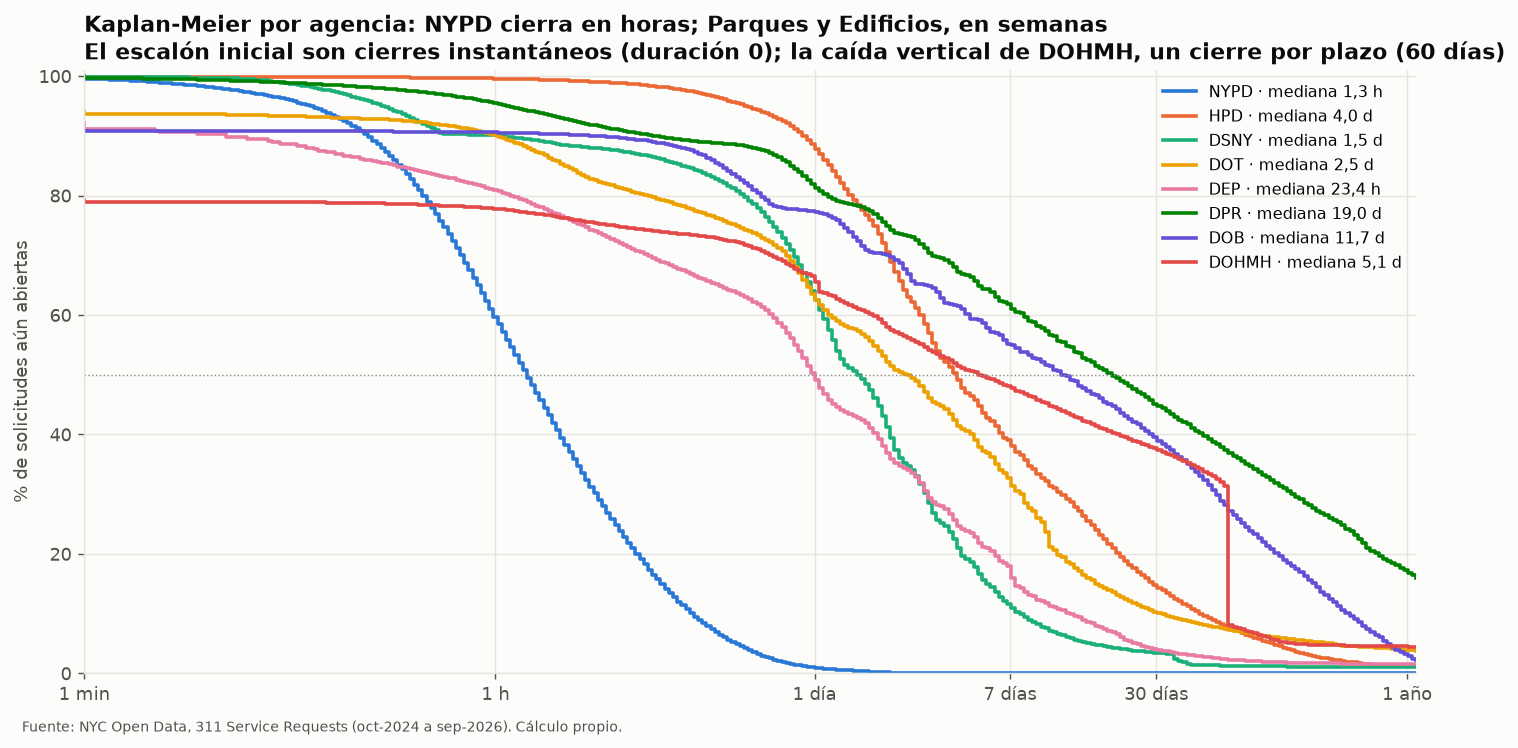

In [8]:
figura("03_kaplan_meier_agencias.png")

In [9]:
tabla("km_boroughs")[["borough", "n", "mediana_km_dias", "mediana_ic_inf", "mediana_ic_sup", "pct_cerradas_7d"]]

,borough,n,mediana_km_dias,mediana_ic_inf,mediana_ic_sup,pct_cerradas_7d
0,BROOKLYN,2277063,0.342,0.340,0.345,80.861
1,QUEENS,1829773,0.225,0.223,0.226,83.258
2,BRONX,1656465,0.502,0.498,0.505,81.404
3,MANHATTAN,1482757,0.590,0.583,0.597,78.407
4,STATEN ISLAND,292145,0.689,0.678,0.701,80.932
5,SIN DATO,6475,5.862,5.208,6.618,52.062


In [10]:
tabla("km_canales")[["canal", "n", "mediana_km_dias", "mediana_ic_inf", "mediana_ic_sup", "pct_cerradas_7d"]]

,canal,n,mediana_km_dias,mediana_ic_inf,mediana_ic_sup,pct_cerradas_7d
0,Web,3386596,0.253,0.251,0.254,83.313
1,Teléfono,1914064,1.911,1.904,1.917,71.550
2,App móvil,1647597,0.093,0.092,0.093,95.353
3,Otro/desconocido,596421,3.130,3.094,3.173,59.267


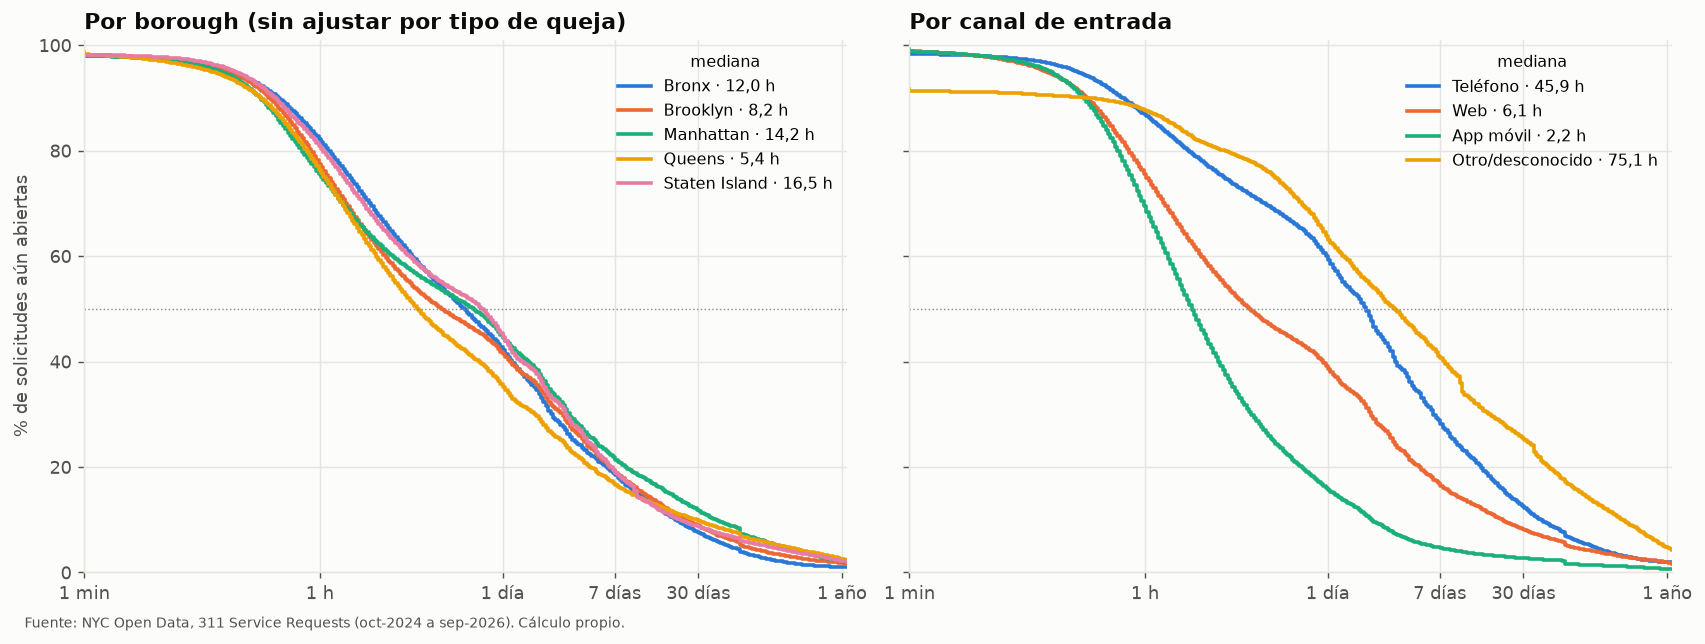

In [11]:
figura("04_kaplan_meier_borough_y_canal.png")

In [12]:
from nyc311.etiquetas import tipo_es
t = tabla("km_tipos_queja").head(20)
t.insert(1, "tipo_es", t["tipo_queja"].map(tipo_es))
t[["tipo_queja", "tipo_es", "n", "pct_censuradas", "mediana_km_dias", "mediana_ic_inf", "mediana_ic_sup",
   "promedio_ingenuo_cerradas_dias"]]

,tipo_queja,tipo_es,n,pct_censuradas,mediana_km_dias,mediana_ic_inf,mediana_ic_sup,promedio_ingenuo_cerradas_dias
0,Illegal Parking,Estacionamiento ilegal,1168641,0.011,0.064,0.064,0.064,0.129
1,Noise - Residential,Ruido residencial,870335,0.033,0.053,0.053,0.053,0.136
2,HEAT/HOT WATER,Calefacción / agua caliente,653263,2.506,1.782,1.778,1.787,1.912
3,Blocked Driveway,Entrada de garaje bloqueada,364643,0.016,0.073,0.072,0.073,0.144
4,Noise - Street/Sidewalk,Ruido en calle / acera,349465,0.031,0.042,0.042,0.042,0.088
5,UNSANITARY CONDITION,Condición insalubre (vivienda),252808,1.646,11.411,11.326,11.524,23.188
6,Street Condition,Estado de la calzada,190371,5.996,1.475,1.432,1.509,4.050
7,PLUMBING,Plomería (vivienda),152193,1.978,8.617,8.450,8.774,21.858
8,Water System,Sistema de agua,148845,1.528,0.144,0.140,0.149,4.298
9,Abandoned Vehicle,Vehículo abandonado,140327,0.021,0.091,0.090,0.092,0.190


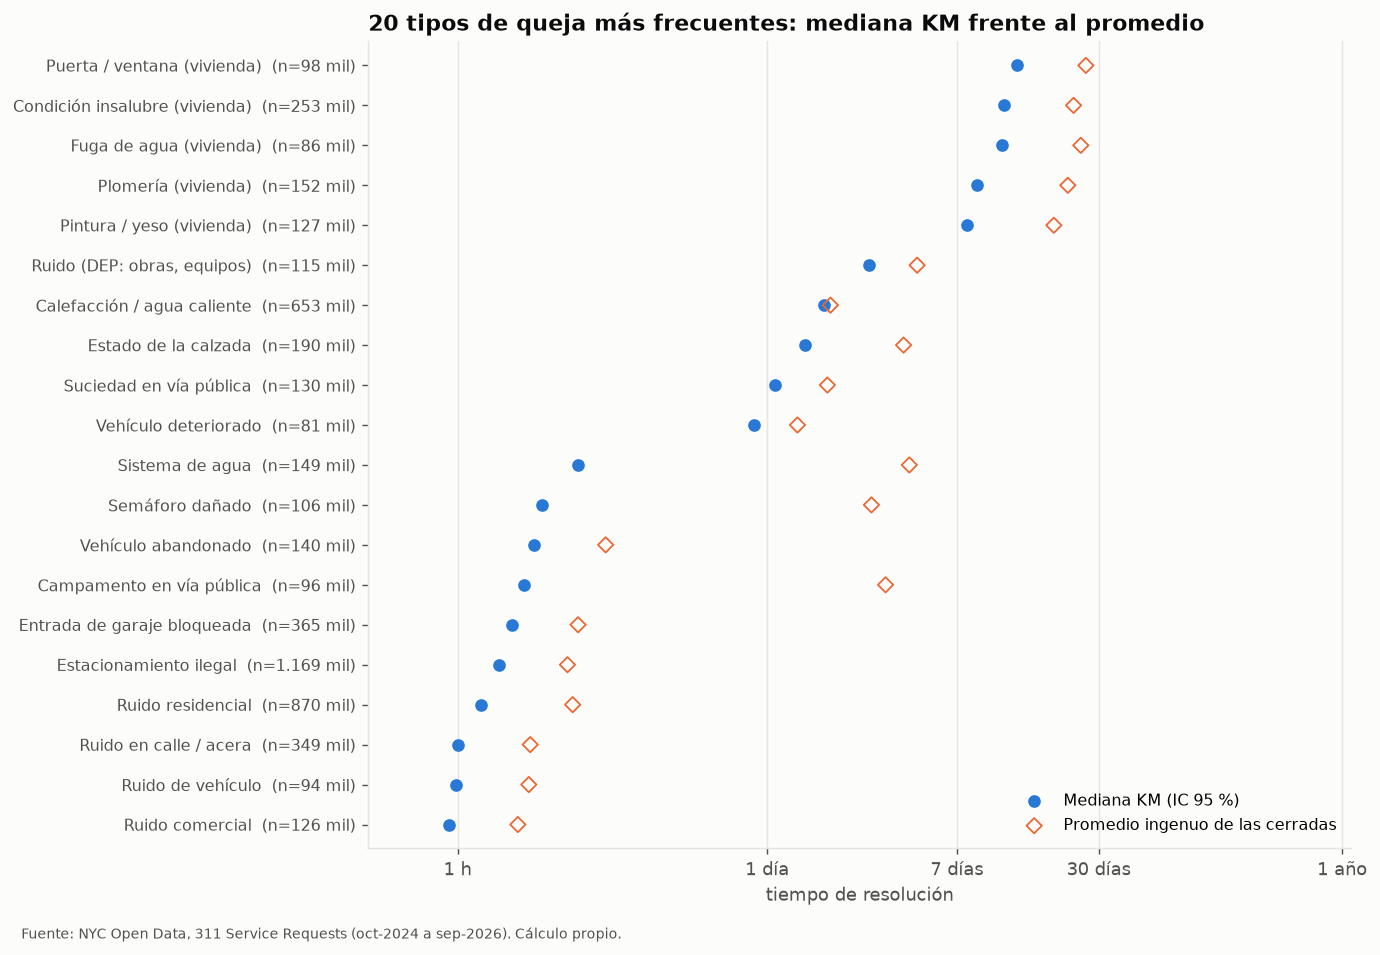

In [13]:
figura("05_medianas_por_tipo_de_queja.png")

## 2.4 Log-rank

H0: todas las curvas del grupo son iguales. Con millones de filas cualquier diferencia mínima es «significativa»;
la prueba confirma que las diferencias no son azar, pero **el tamaño** se lee en las medianas y en los HR.

In [14]:
lr = tabla("logrank")
lr.assign(p_valor=lr["p_valor"].map(lambda p: f"{p:.1e}"))

,dimension,grupos,chi2,gl,p_valor
0,agencia,10,"7,051,706.131",9,0.0e+00
1,tipo_queja,21,"6,128,322.069",20,0.0e+00
2,borough,5,"12,097.497",4,0.0e+00
3,canal,4,"834,874.257",3,0.0e+00
4,borough | Illegal Parking,5,"22,392.035",4,0.0e+00
5,borough | Noise - Residential,5,"56,251.990",4,0.0e+00
6,borough | HEAT/HOT WATER,5,"10,810.725",4,0.0e+00
7,borough | Street Condition,5,"1,389.557",4,1.3e-299
8,borough | Rodent,5,"1,906.661",4,0.0e+00
